In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
label_encoder=LabelEncoder()
encoder_one_hot=OneHotEncoder()

In [3]:
student_df=pd.read_csv('/content/drive/MyDrive/AI ML-Course/AI ML-Dataset/Student_Depression_Dataset.csv')

In [4]:
student_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [5]:
student_df.shape

(4464, 13)

In [6]:
student_df.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [7]:
student_num=student_df.select_dtypes(include='number').columns
student_cat=student_df.select_dtypes(include='object').columns

In [8]:
student_num

Index(['Age', 'Current_semester', 'CGPA', 'Cost_without_study'], dtype='object')

In [9]:
student_df[student_num].isna().sum()

,0
Age,0
Current_semester,0
CGPA,0
Cost_without_study,0


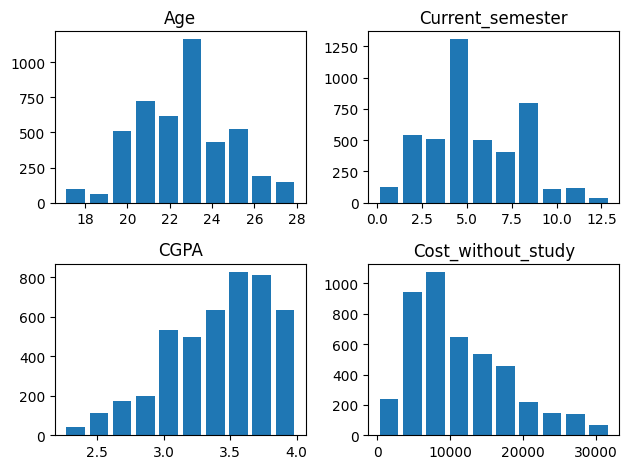

In [10]:
for i,col in enumerate(student_num,1):
  plt.subplot(2,2,i)
  plt.hist(student_df[col],rwidth=0.8)
  plt.title(col)
plt.tight_layout()
plt.show()

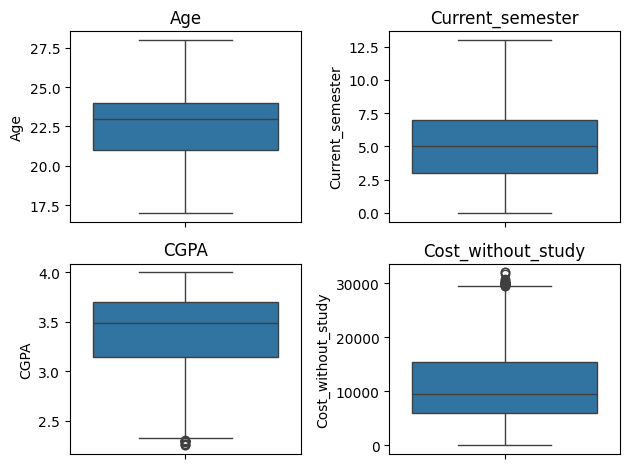

In [11]:
for i,col in enumerate(student_num,1):
  plt.subplot(2,2,i)
  sns.boxplot(student_df[col])
  plt.title(col)
plt.tight_layout()
plt.show()

In [12]:
Q1=student_df[student_num].quantile(0.25)
Q3=student_df[student_num].quantile(0.75)
IQR=Q3-Q1

upper_limit=Q3+(1.5*IQR)
lower_limit=Q1-(1.5*IQR)

# Fetching outlier
outlier=((student_df[student_num]>upper_limit) | (student_df[student_num]<lower_limit))

# Method 1 removing outlier
student_df=student_df[~outlier.any(axis=1)]


student_df[student_num]=student_df[student_num].clip(lower=lower_limit,upper=upper_limit, axis=1)

In [13]:
student_df.duplicated().sum()

np.int64(0)

In [14]:
student_df.shape

(4416, 13)

In [15]:
student_df.drop_duplicates(inplace=True)

In [16]:
student_df[student_cat].isna().sum()

,0
Gender,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
friend_circle,0
Health_condition,0
Home_division,0
Depression,0


In [17]:
student_cat

Index(['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle', 'Health_condition', 'Home_division',
       'Depression'],
      dtype='object')

In [18]:
#LabelEncoder in target column
student_df['Depression']=label_encoder.fit_transform(student_df['Depression'])

In [19]:
student_df[student_cat].tail()

,Gender,Family_background,Relationship_status,Marital_status,Living_style,friend_circle,Health_condition,Home_division,Depression
4459,Female,Middle class,In a Relationship,Separated,Family,No,Critical,Khulna,1
4460,Male,Lower Middle class,Single,Unmarried,Family,No,Normal,Rajshahi,1
4461,Female,Middle class,In a Relationship,Married,Bachelor,No,Good,Rajshahi,0
4462,Female,Middle class,Complicated,Married,Family,Yes,Normal,Barisal,0
4463,Female,Lower Middle class,Single,Unmarried,Family,Yes,Abnormal,Barisal,1


In [20]:
#OrdinalEncoder fro feature columns
student_df['Health_condition'].unique()

array(['Critical', 'Abnormal', 'Good', 'Normal'], dtype=object)

In [21]:
encoder_health=OrdinalEncoder(
    categories=[['Normal','Good','Abnormal','Critical']]
)

student_df['Health_condition']=encoder_health.fit_transform(student_df[['Health_condition']])

In [22]:
student_df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,1


In [23]:
student_df['Family_background'].unique()

array(['Middle class', 'Lower Middle class', 'Rich class'], dtype=object)

In [24]:
encoder_family_background=OrdinalEncoder(
    categories=[['Rich class','Middle class','Lower Middle class']]
)

student_df['Family_background']=encoder_family_background.fit_transform(student_df[['Family_background']])

In [25]:
student_df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,1.0,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1
1,Male,19,1.0,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1
2,Male,23,1.0,Single,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,1
3,Male,20,1.0,Complicated,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,0
4,Female,21,1.0,Single,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,1


In [26]:
#One_Hot_Encoder for Gender column
encoded_data=encoder_one_hot.fit_transform(student_df[['Gender']])

encoded_df=pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_one_hot.get_feature_names_out(['Gender']),
    index=student_df.index
)

In [27]:
#One_Hot_Encoder for Relationship_status column
encoded_relationship=encoder_one_hot.fit_transform(student_df[['Relationship_status']])

relationship_df=pd.DataFrame(
    encoded_relationship.toarray(),
    columns=encoder_one_hot.get_feature_names_out(['Relationship_status']),
    index=student_df.index
)

#One_Hot_Encoder for Marital_status column
encoded_martial_status=encoder_one_hot.fit_transform(student_df[['Marital_status']])

martial_df=pd.DataFrame(
    encoded_martial_status.toarray(),
    columns=encoder_one_hot.get_feature_names_out(['Marital_status']),
    index=student_df.index
)

#One_Hot_Encoder for Living_style column
encoded_living_status=encoder_one_hot.fit_transform(student_df[['Living_style']])

living_df=pd.DataFrame(
    encoded_living_status.toarray(),
    columns=encoder_one_hot.get_feature_names_out(['Living_style']),
    index=student_df.index
)

#One_Hot_Encoder for Home_division column
encoded_home_division=encoder_one_hot.fit_transform(student_df[['Home_division']])

home_division_df=pd.DataFrame(
    encoded_home_division.toarray(),
    columns=encoder_one_hot.get_feature_names_out(['Home_division']),
    index=student_df.index
)

final_student_df=pd.concat([student_df.drop(columns=['Gender','Relationship_status','Marital_status','Living_style','Home_division']),encoded_df,relationship_df,martial_df,living_df,home_division_df],axis=1)

#convert friend_circle using LabelEncoder
final_student_df['friend_circle']=label_encoder.fit_transform(final_student_df['friend_circle'])

In [28]:
student_df['Home_division'].unique()

array(['Chittagong', 'Dhaka', 'Rajshahi', 'Mymensingh', 'Barisal',
       'Rangpur', 'Khulna', 'Sylhet'], dtype=object)

In [29]:
final_student_df.head()

,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression,Gender_Female,Gender_Male,...,Living_style_Bachelor,Living_style_Family,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
0,22,1.0,8,3.43,1,3.0,10113,1,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,19,1.0,2,3.70,1,2.0,13815,1,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,23,1.0,8,3.28,0,2.0,15450,1,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,20,1.0,2,3.77,0,1.0,17413,0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,21,1.0,1,4.00,0,2.0,16693,1,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [30]:

X=final_student_df.drop('Depression',axis=1)
y=final_student_df['Depression']

X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,random_state=42)

print(X_train.shape)
print(X_test.shape)
print(X_train.head())

(3532, 25)
(884, 25)
      Age  Family_background  Current_semester  CGPA  friend_circle  \
3400   23                1.0                 5  3.58              1   
3913   20                1.0                 9  3.00              0   
660    18                1.0                 3  3.75              1   
4390   24                0.0                 2  3.20              1   
3082   24                1.0                 8  2.89              0   

      Health_condition  Cost_without_study  Gender_Female  Gender_Male  \
3400               3.0               18000            0.0          1.0   
3913               2.0               19681            0.0          1.0   
660                2.0               10294            1.0          0.0   
4390               0.0               21845            1.0          0.0   
3082               3.0                6100            1.0          0.0   

      Relationship_status_Complicated  ...  Living_style_Bachelor  \
3400                              0.0 

In [31]:
X_train_num_cols=X_train.select_dtypes(include='number')
X_test_num_cols=X_test.select_dtypes(include='number')

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train_num_cols)
X_test_scaled=scaler.transform(X_test_num_cols)

X_train_num_scaled=pd.DataFrame(
    X_train_scaled,
    columns=X_train_num_cols.columns,
    index=X_train_num_cols.index
)

X_test_num_scaled=pd.DataFrame(
    X_test_scaled,
    columns=X_test_num_cols.columns,
    index=X_test_num_cols.index
)

X_test_num_scaled.head()

,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Gender_Female,Gender_Male,Relationship_status_Complicated,...,Living_style_Bachelor,Living_style_Family,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet
1635,-0.800775,1.389689,1.015095,0.514474,0.629323,-0.999319,-0.782484,-1.086392,1.086392,-0.21996,...,0.892492,-0.892492,-0.290574,-0.317261,1.389648,-0.376250,-0.290001,-0.347727,-0.298521,-0.330073
1461,-2.289374,1.389689,-0.546454,0.384455,-1.589009,-0.073402,-0.782484,-1.086392,1.086392,-0.21996,...,-1.120459,1.120459,-0.290574,-0.317261,-0.719607,2.657805,-0.290001,-0.347727,-0.298521,-0.330073
4010,-0.800775,-0.206014,1.405482,0.384455,-1.589009,-0.999319,1.358001,-1.086392,1.086392,-0.21996,...,0.892492,-0.892492,-0.290574,-0.317261,-0.719607,-0.376250,-0.290001,-0.347727,3.349844,-0.330073
1739,1.184023,-0.206014,0.234321,0.046405,0.629323,-0.073402,-0.333518,0.920478,-0.920478,-0.21996,...,-1.120459,1.120459,-0.290574,-0.317261,1.389648,-0.376250,-0.290001,-0.347727,-0.298521,-0.330073
144,-0.304575,1.389689,-0.546454,0.020401,0.629323,0.852515,-0.663276,-1.086392,1.086392,-0.21996,...,-1.120459,1.120459,-0.290574,-0.317261,1.389648,-0.376250,-0.290001,-0.347727,-0.298521,-0.330073
